# Сербская LLM: данные, модели и одинаковые пробы генерации

Собственное обучение с нуля: две модели около 41M, три архитектуры около 283M,
контрольное продолжение A и основная ветка B на расширенном корпусе.
После описания каждой модели — одни и те же пять начал текста.
Ноутбук использует локальные `best.pt`; веса не меняет.


In [1]:
from pathlib import Path
import gc
import json
import sys
from datetime import datetime
from zoneinfo import ZoneInfo

import torch
from IPython.display import Markdown, display

ROOT = Path.cwd()
if not (ROOT / "src/serbian_llm").is_dir():
    raise RuntimeError("Открой ноутбук из каталога с README.md и pyproject.toml.")
sys.path.insert(0, str(ROOT / "src"))

from serbian_llm.experiments import RUN_NAMES, read_metrics, run_summary
from serbian_llm.inference import Generator
from serbian_llm.utils import read_json, read_jsonl

DEVICE = "cuda:2" if torch.cuda.device_count() > 2 else ("cuda:0" if torch.cuda.is_available() else "cpu")
PRECISION = "bf16" if DEVICE.startswith("cuda") else "fp32"
print(datetime.now(ZoneInfo("Europe/Moscow")).strftime("%d.%m.%Y %H:%M МСК"))
print("Устройство:", DEVICE, "точность:", PRECISION)


25.10.2026 19:44 МСК
Устройство: cuda:0 точность: bf16


## Данные

Сербская кириллица: Wikipedia `20231101.sr` и FineWeb2 `srp_Cyrl`.
Исходный корпус содержит 499,5 МБ очищенного текста всех разбиений и 80,16M
train-токенов. Расширенный train — 267,31M токенов. Validation/test при расширении
сохранены побайтово; test не используется для выбора модели.


In [2]:
corpora = {
    "Исходный": ROOT / "data/serbian_mix_v2",
    "Расширенный": ROOT / "data/serbian_expanded_v3",
}
lines = ["| Корпус | Train-документы | Train-токены | UTF-8 train, МБ | Токенов/слово |",
         "|---|---:|---:|---:|---:|"]
for label, folder in corpora.items():
    manifest = read_json(folder / "corpus/manifest.json")
    stats = read_json(folder / "bpe8k/token_stats.json")["splits"]["train"]
    lines.append(f"| {label} | {stats['documents']:,} | {stats['tokens']:,} | "
                 f"{stats['text_bytes']/1e6:.1f} | {stats['tokens_per_word']:.3f} |")
display(Markdown("\n".join(lines)))


| Корпус | Train-документы | Train-токены | UTF-8 train, МБ | Токенов/слово |
|---|---:|---:|---:|---:|
| Исходный | 78,484 | 80,159,914 | 489.9 | 1.963 |
| Расширенный | 250,886 | 267,310,738 | 1669.2 | 1.909 |

## Обработка

NFC, длина и число слов, язык по метаданным, сербская письменность, повторы,
списки/неоднозначности Wikipedia; exact и MinHash-дедупликация.
При расширении удаляются служебные хвосты Wikipedia и явные меню/таблицы,
а документы с совпадениями с holdout не попадают в train.
Удаление совпадений новой стадии не отменяет прежнее обучение родителя на них.
Код: `streaming.py`, `preparation.py`, `data.py`, `expansion.py`.


In [3]:
audit = read_json(ROOT / "data/serbian_expanded_v3/corpus/split_audit.json")
print({key: value for key, value in audit.items() if key != "shared_paragraph_examples"})

seen_sources = set()
for row in read_jsonl(ROOT / "data/serbian_expanded_v3/corpus/train.jsonl"):
    source = row.get("source", "local")
    if source not in seen_sources:
        print("\nИСТОЧНИК:", source)
        print(row["text"][:800])
        seen_sources.add(source)
    if len(seen_sources) == 2:
        break


{'exact_cross_split_documents': 0, 'shared_long_paragraph_occurrences': 8, 'minimum_paragraph_characters': 200, 'shared_paragraph_split_pairs': {'validation:test': 8}, 'note': 'Shared paragraphs can be quotations or boilerplate; inspect before interpreting as leakage.'}

ИСТОЧНИК: wikimedia/wikipedia
Мирослав (; умро 949) је био краљ Хрватске од 945. до 949. године.

Биографија 
Мирослав је припадао династији Трпимировића. Био је старији син хрватског краља Крешимира I (935—945) и брат Михаила Крешимира II. На власт је дошао након очеве смрти. Летопис попа Дукљанина бележи грађански рат који је вођен у Хрватској током Мирослављеве владавине. Рат је покренуо краљев брат Михаило. Мирослав је изгубио већину земаља у Босни. Њих заузима српски кнез Часлав Клонимировић. Византинци су настојали да поврате своје поседе у Далмацији. Хрватска флота је у то време имала око 30 бродова. Мирослав је 949. године убијен од стране кнеза Прибине. Михаило га је наследио на хрватском престолу.

Породично 


ИСТОЧНИК: HuggingFaceFW/fineweb-2
Према програму посете шефа руске државе, Путину ће на Аеродрому „Никола Тесла“ бити приређен дочек, након којег ће бити одржана церемонија полагања венаца на Гробљу ослободилаца Београда и Црвеноармејцу.
Церемонија свечаног дочека руског председнка испред Палате Србија предвиђена је за 12.45 сати, након чега ће уследити састанак у ужем формату двојице председника, Вучића и Путина.
Сат након тога планиран је састанак делегација Србије и Русије, а потом и потписивање билатералних докумената у присуству двојице председника.
За по подне је предвиђена церемонија уручења Ордена Александра Невског председнику Србије Александру Вучићу.
Орден Вучићу ће уручити председник Путин. Двојица председника ће се након тога обратити медијима. А по давању изјава планиран је обилазак Храма Светог Саве.
Завршне


## Токенизатор

Один ByteLevel BPE-8192, обученный на исходном train: NFC, без lowercasing,
с сохранением сербских диакритических знаков. PAD/BOS/EOS/UNK; формат документа
`BOS + text + EOS`, бинарные файлы uint16. Новый корпус кодируется тем же BPE.
UNK=0 у byte-level токенизации не является самостоятельной оценкой качества.
Код: `tokenization.py`.


In [4]:
from tokenizers import Tokenizer

tokenizer_folder = ROOT / "data/serbian_mix_v2/bpe8k"
tokenizer = Tokenizer.from_file(str(tokenizer_folder / "tokenizer.json"))
meta = read_json(tokenizer_folder / "tokenizer_meta.json")
print("Размер словаря:", tokenizer.get_vocab_size())
print("Специальные токены:", meta["special_ids"])
text = "Милица је јуче отишла у библиотеку. Тамо је читала књигу."
encoded = tokenizer.encode(text)
print("Исходный текст:", text)
print("ID:", encoded.ids)
print("Обратное преобразование:", tokenizer.decode(encoded.ids))


Размер словаря: 8192
Специальные токены: {'[PAD]': 0, '[BOS]': 1, '[EOS]': 2, '[UNK]': 3}
Исходный текст: Милица је јуче отишла у библиотеку. Тамо је читала књигу.
ID: [4846, 538, 299, 7854, 4303, 729, 289, 3250, 1803, 17, 444, 822, 299, 2011, 542, 7153, 17]
Обратное преобразование: Милица је јуче отишла у библиотеку. Тамо је читала књигу.


## Архитектуры и обучение

Decoder-only, контекст 512, causal SDPA, pre-RMSNorm, SwiGLU, GQA,
связанные embedding и LM head. Основная позиционная схема — RoPE; absolute — абляция.
AdamW + BF16, WSD, clipping=1; effective batch=32, 16 384 токена на шаг.
Каждый из первых пяти запусков получил 327,68M предъявлений токенов.
A/B начинают с Deep №2 и планируют ещё 500,01M токенов каждая.
RMSNorm контролирует масштаб; SwiGLU — гейтинг FFN; GQA и связанные embeddings экономят параметры.
Код модели — `model.py`, обучения — `training.py`, сохранения — `checkpoints.py`.

В таблице время чистых train-шагов из последнего checkpoint, без eval/генераций/IO.
Для незавершённых стадий это время только до указанного сохранённого шага.


In [5]:
lines = ["| Запуск | Параметры | Шаг / план | Чистое время, ч | Шаг времени | Best step | Статус |",
         "|---|---:|---:|---:|---:|---:|---|"]
for name in RUN_NAMES:
    s = run_summary(ROOT / "runs" / name)
    status = "завершён" if s["complete"] else "не завершён"
    lines.append(f"| {name} | {s['parameters']:,} | {s['step']:,} / {s['max_steps']:,} | "
                 f"{s['training_seconds']/3600:.2f} | {s['timing_checkpoint_step']:,} | "
                 f"{s['best_step']:,} | {status} |")
display(Markdown("\n".join(lines)))


| Запуск | Параметры | Шаг / план | Чистое время, ч | Шаг времени | Best step | Статус |
|---|---:|---:|---:|---:|---:|---|
| absolute_41m | 41,109,888 | 20,000 / 20,000 | 2.19 | 20,000 | 20,000 | завершён |
| rope_41m | 40,913,280 | 20,000 / 20,000 | 2.74 | 20,000 | 20,000 | завершён |
| serbian_283m_1 | 283,170,240 | 20,000 / 20,000 | 1.84 | 20,000 | 20,000 | завершён |
| serbian_283m_2 | 283,183,872 | 20,000 / 20,000 | 2.16 | 20,000 | 20,000 | завершён |
| serbian_283m_3 | 283,173,824 | 20,000 / 20,000 | 4.75 | 20,000 | 20,000 | завершён |
| deep_continue_A | 283,183,872 | 12,480 / 30,518 | 1.30 | 12,000 | 500 | не завершён |
| deep_continue_B | 283,183,872 | 12,110 / 30,518 | 1.30 | 12,000 | 11,500 | не завершён |

## Сопоставимая validation

У первых пяти моделей одинаковые 32 packed-окна; у A/B — одинаковые 64 окна.
Поэтому графики разных стадий разделены. Это не документная perplexity:
полная validation сбрасывает контекст на документе и оценивает каждый content-токен
ровно один раз, stride=256, EOS исключён.


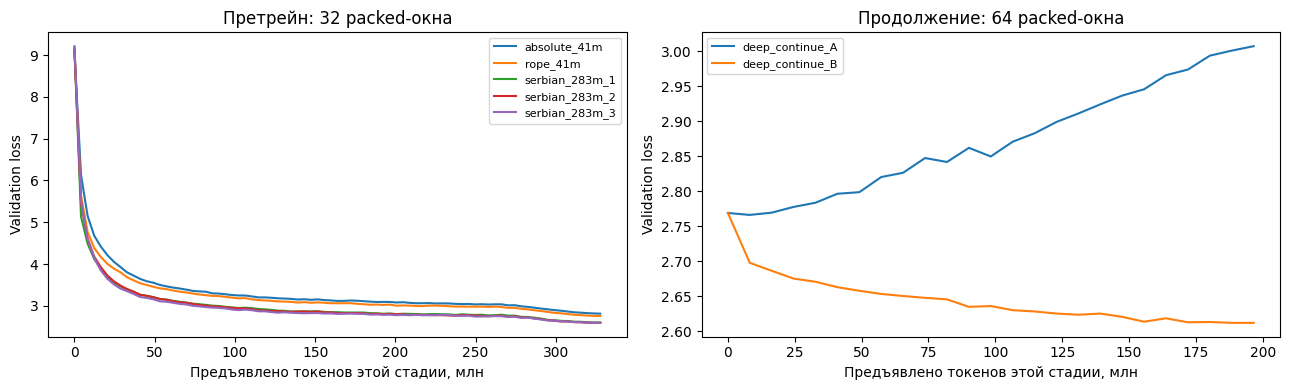

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, names, title in [(axes[0], RUN_NAMES[:5], "Претрейн: 32 packed-окна"),
                         (axes[1], RUN_NAMES[5:], "Продолжение: 64 packed-окна")]:
    for name in names:
        rows = [r for r in read_metrics(ROOT / "runs" / name / "metrics.jsonl") if "validation_loss" in r]
        ax.plot([r["processed_input_tokens"] / 1e6 for r in rows],
                [r["validation_loss"] for r in rows], label=name)
    ax.set(title=title, xlabel="Предъявлено токенов этой стадии, млн", ylabel="Validation loss")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


In [7]:
summary = read_json(ROOT / "runs/review_283m_20261025/summary.json")
lines = ["| Модель | Полная validation PPL | Bits/byte |", "|---|---:|---:|"]
for name, record in summary.items():
    if "full_validation" in record:
        values = record["full_validation"]
        lines.append(f"| {name} | {values['perplexity']:.3f} | {values['bits_per_byte']:.5f} |")
display(Markdown("\n".join(lines)))
print("Полная оценка A/B в этот отчёт пока не включена.")


| Модель | Полная validation PPL | Bits/byte |
|---|---:|---:|
| rope_41m | 18.613 | 0.69268 |
| serbian_283m_1 | 16.608 | 0.66569 |
| serbian_283m_2 | 16.521 | 0.66445 |
| serbian_283m_3 | 16.664 | 0.66647 |

Полная оценка A/B в этот отчёт пока не включена.


## Одинаковые пробы генерации

Для каждой модели: эти пять начал, seed=42, temperature=0.8, top_k=40,
до 128 новых токенов; EOS может завершить текст раньше. Генерируется продолжение.
Это ручные качественные пробы, не автоматический benchmark с правильными ответами.
Смотри на сербскую грамматику, тему, персонажей, передачу книги и повторы.
Ниже сохраняются все результаты, включая неудачные.


In [8]:
PROMPTS = [
    "Небо је плаво, а сунце",
    "Милица је јуче отишла у библиотеку. Тамо је",
    "У нашем граду постоји мали парк. Људи тамо долазе да шетају и да се одморе. Поред стазе расте високо дрвеће, а у средини парка",
    "Ана је дала књигу Марку. Марко је затим дао ту књигу Јелени. На крају је књига код",
    "Ана и Милица су кренуле на излет. Понеле су храну и воду, али су заборавиле кишобран. Када су стигле до језера, почела је јака киша. У близини су угледале малу кућу. Ана је предложила да",
]
GENERATION = dict(max_new_tokens=128, temperature=0.8, top_k=40, seed=42)
GENERATIONS = {}


def compare_prompts(name):
    generator = Generator(ROOT / "runs" / name / "best.pt", DEVICE, PRECISION)
    try:
        state = generator.checkpoint["state"]
        print(name, "| checkpoint step:", state["step"], "| precision:", generator.precision)
        results = []
        for index, prompt in enumerate(PROMPTS, 1):
            result = generator.generate(prompt, **GENERATION)
            results.append(result)
            print(f"\n{index}) {prompt}")
            print(result["completion"])
            print("[новых токенов:", result["generated_tokens"], "]")
        GENERATIONS[name] = {"checkpoint_step": state["step"], "examples": results}
    finally:
        del generator
        gc.collect()
        if DEVICE.startswith("cuda"):
            torch.cuda.empty_cache()


### Absolute 41M

41 109 888 параметров, 24×384, FFN 1024, GQA 6/2. Обучаемые absolute positions
вместо RoPE — контроль позиционной схемы. Чистое обучение: 2 ч 12 мин.
Конфиг: `configs/ablation_absolute.json`.


In [9]:
compare_prompts("absolute_41m")


absolute_41m | checkpoint step: 20000 | precision: bf16



1) Небо је плаво, а сунце
 и птице. Најбоља плавуша је Пилићи.

Референце

Литература 
З. Шуица, Лепа Госибо-Књажевац, 2009.

Спољашње везе 
Официус Шуица

Ш
[новых токенов: 62 ]



2) Милица је јуче отишла у библиотеку. Тамо је
 и снимила представу на којој се на друштвеним мрежама види како се ради, а који се ту наизглед ни на који начин не може назвати само „мистеријом“ јер се није радило о „хуманизму“.
Очигледно је да је он то већ написао на филму, али је и то, како каже, требало да се ојача, а да јој она не треба.
– Рекао сам да се не зна одакле ће, после неког времена, поново појавити, али ми се јако свиђа и не желим да ми каже, али мислим да сам
[новых токенов: 128 ]



3) У нашем граду постоји мали парк. Људи тамо долазе да шетају и да се одморе. Поред стазе расте високо дрвеће, а у средини парка
 и тротоара. У овом парку, на обали је мали бунар, а на његовом дну стоји киша.
Парк је изузетно комплексакуларан. Са обе стране парка налази се велики број пешчаних миља и отворен је за шетњу до самог језера. Останак је познат по локалним местима, укључујући пашњаке и мочваре, а парк је познат по томе што је познат по томе што је једна од најбољих пешчаних миља на свету.
Оно што је специфичније је да парк има све оазе у парку, као што су
[новых токенов: 128 ]



4) Ана је дала књигу Марку. Марко је затим дао ту књигу Јелени. На крају је књига код
 ње испричала Марку, коју је читала и рекла: „Сам је био господар моје земље, па те је на крају читала; па би било суђено да не говорим”.

Референце

Литература

Спољашње везе 
Plamentary of Generalogy, The Second Souther article article on catalcales.
Footballer, Martin, National Academy of Byzantine
[новых токенов: 128 ]



5) Ана и Милица су кренуле на излет. Понеле су храну и воду, али су заборавиле кишобран. Када су стигле до језера, почела је јака киша. У близини су угледале малу кућу. Ана је предложила да
 се одморе.

Она је кренула у ходање, а она је кренула у шетњу. Нажалост, на излетима су радосно ходали. Била је то велика радост. Заузима мноштво кафића из разних градова.

Уочи Божића, када је краљица Јелисавета остала у кући, пут је поново почео да тече, а мноштво њих је ишло према граду. Због неспретног рада, и када је напољу било хладно, у ходнику је дошло доста воде па су се људи враћали кући
[новых токенов: 128 ]


### RoPE 41M — базовая архитектура

40 913 280 параметров, 24×384, FFN 1024, GQA 6/2. RoPE заменяет таблицу позиций;
RMSNorm, SwiGLU и связанные embeddings сохраняются. Чистое обучение: 2 ч 45 мин.
Конфиг: `configs/main_rope.json`.


In [10]:
compare_prompts("rope_41m")


rope_41m | checkpoint step: 20000 | precision: bf16



1) Небо је плаво, а сунце
 и тропска чуда, а на њему је и више врста птица, али и животиња и птица.

Доње и горје је само једна врста у свету, једна од њих је Зелена чуда и једна мочварна чуда.

Понашање 

Патуљак или пепељана, пепељана или вунена чула, је врста из мочварног подручја. Познато је и као врста бора. У Србији и Црној Гори, има типичну вулканску климу.

Клобук 
К
[новых токенов: 128 ]



2) Милица је јуче отишла у библиотеку. Тамо је
 већ била на путу. Дошла је и њена мајка, која је била запослена на Дјечијем Котору те упознаје са српским породицама.
Милица је, како тврди, у библиотеци библиотеке. О њој нема података.
- Она је, као и она, веома заинтересована за овај случај – додаје Милица, која, како каже, већ годинама ради као уредник књижног Котора.
- Мој отац је радио и одгајао. У једној и другој библиотеци је било доста оних који су се и дружили. Научила сам да ми се придруж
[новых токенов: 128 ]



3) У нашем граду постоји мали парк. Људи тамо долазе да шетају и да се одморе. Поред стазе расте високо дрвеће, а у средини парка
 и трамваја на стази на стари начин је украшавана и савремена стаза која је однела живот.
Занимљива је само једна легенда, да се овде у Новом Саду, поред старих стаза, одржава и низ других културних манифестација које треба посетити. У Новом Саду, по најавама, постоји, али и изузетно лепа изложба о томе како ће се одморити. У Новој Пазови, у парку се одржавају летњи и летњи догађаји. Идеја је да се у Новом Саду, у Новом Саду, отвори изложба
[новых токенов: 128 ]



4) Ана је дала књигу Марку. Марко је затим дао ту књигу Јелени. На крају је књига код
 ње снимила приче о двоје браће и сестара, који су их и сами заменили. Непосредно пре него што су се преселили у Француску, Марија је пронашла троје браће и сестара које су се преселиле из Француске.

У време када је Марија родила шесторо деце, Марија је имала три сина и једну ћерку. Од ње је било дванаесторо деце.

На дан школе, Марија је одведена на летовање у Риму, а Марија је добила ћерку.

Сезоне

Улоге

Референце

[новых токенов: 128 ]



5) Ана и Милица су кренуле на излет. Понеле су храну и воду, али су заборавиле кишобран. Када су стигле до језера, почела је јака киша. У близини су угледале малу кућу. Ана је предложила да
 се нада да ће на неко време наилазити на тешке буре, али је била веома опрезна.
– У понедељак су се људи окупљали и ишли ка селу. Засад смо били мало боље и мало мазги. Ускоро је дошло до буре. После су се кретали, али су били веома опрезни. Одмах је дошао велики пожар, али их је полиција разбила – каже Милица.
Она је објаснила да је и раније бура почела да пада, али да се ту не може видети брза снег.
– К
[новых токенов: 128 ]


### №1 Wide 283M

283 170 240 параметров, 28×960, FFN 2560, GQA 15/5. Больше ширины и ёмкости;
сравниваем с глубокой моделью при близком числе параметров. Чистое обучение: 1 ч 50 мин.
Конфиг: `configs/main_rope_1.json`.


In [11]:
compare_prompts("serbian_283m_1")


serbian_283m_1 | checkpoint step: 20000 | precision: bf16



1) Небо је плаво, а сунце
 и тропско.
Она на северу, у централном делу Србије,
копно је на северу.
Температура ваздуха у Београду је од 2 до 5,
од 5 до 10 степени.
Ветар слаб и умерен, у Београду слаб, у већини области
од 5 до 7 степени.
Јутарња температура ваздуха у Београду је око 2,
од 8 до 9 степени.
Јутарња температура ваздуха у Београду је око 7 степени.
Најнижа температура ваздуха у Београду је између 6 и 9 степени.
У току дана у Београду највише сунчаних, у
[новых токенов: 128 ]



2) Милица је јуче отишла у библиотеку. Тамо је
 и упознала нове људе, а било је и доста позитивних информација.
-Мој први сусрет са књижевном публиком био је у издању Центра за културу. Односила сам се са библиотекарицом која је први пут посетила наш сајт, а сада је имала прилику да представи моју књигу, коју је припремио, како бих сазнала нешто више о раду библиотеке. Она је, такође, показала да можемо да се дружимо и дамо им прилику да науче нешто и да је много лепо што смо заједно урадили – рекла је Милица.
Она је истакла да
[новых токенов: 128 ]



3) У нашем граду постоји мали парк. Људи тамо долазе да шетају и да се одморе. Поред стазе расте високо дрвеће, а у средини парка
 налазе се густе шуме, клеке и кандила. Некад је било мало стазе која је могла да понесе све што би се могло понети.
У парку се налази и трим стаза коју је прикупио велики број људи, а сада је посетиоци могу да виде и све што се налази у парку, укључујући пјешачке стазе, трим стазе и велике гуме.
У парку се налази велики број пећинских слика из периода римског доба, с обзиром да је то било најтеже за живот у доба Римског царства па и Римског царства. К
[новых токенов: 128 ]



4) Ана је дала књигу Марку. Марко је затим дао ту књигу Јелени. На крају је књига код
но насловљена Орфеј, а на крају је и написао текст Марка.

Спољашње везе 

Књига Марка

Рођени 1828.
Умрли 1839.
Династија Хановер
Едвард Медичи
[новых токенов: 55 ]



5) Ана и Милица су кренуле на излет. Понеле су храну и воду, али су заборавиле кишобран. Када су стигле до језера, почела је јака киша. У близини су угледале малу кућу. Ана је предложила да
 се одморе.
– Ја сам на одмору и сви су мислили да ћу бити на излет. Када смо стигле на излет, отишле смо у стан. Са кишом смо отишле. Ана је рекла да не може да иде у други крај.
– Свако јутро ми је узео воду и ватру, рекао сам јој. Она је понела воду и рекла да ће бити на излет. Онда смо се пробудили из кревета. Ана и Милица су се смејали, а Милица је отишла у други крај. Позвала сам
[новых токенов: 128 ]


### №2 Deep 283M

283 183 872 параметра, 44×768, FFN 2048, GQA 12/4. Более глубокая и узкая модель
при том же параметрическом бюджете. Чистое обучение: 2 ч 10 мин.
Минимальный loss полной validation среди трёх 283M; родитель следующих стадий.
Конфиг: `configs/main_rope_2.json`.


In [12]:
compare_prompts("serbian_283m_2")


serbian_283m_2 | checkpoint step: 20000 | precision: bf16



1) Небо је плаво, а сунце
 плаво.

Осмотски притисак 

Сунце се налази у средини где Сунце плави при дну, а Сунце плави у супротним смеровима што указује на то да је Сунце плаво.

Боја звезда 

Ако сунце плави некога, то значи да ће плавац плавати некога. Ако је сунце плаво, црно и бело, онда је то плава боја. Ако Сунце плави нечији глагол, то значи да га сунце плави. Ако Сунце плави некога, може постати
[новых токенов: 128 ]



2) Милица је јуче отишла у библиотеку. Тамо је
 била у библиотеци и на дан када је требало да буде дочекана са љубављу.
-Била сам тамо све време, све је било добро, радило се о свадби. Било је веома добро. Било је пуно људи које сам помагала, а било је много оних који то нису могли да приуште, поготово када су жене које су ми користиле била деца. Била сам гђа и ја са малом децом која су била гадна, што их је и чинило много срећнијим. То је за сваког човека било нешто на чему ми је највише одговарало, и
[новых токенов: 128 ]



3) У нашем граду постоји мали парк. Људи тамо долазе да шетају и да се одморе. Поред стазе расте високо дрвеће, а у средини парка
 и трим стазе на шеталиштима.
Дугачко трамвајско насеље Лане које се налази на самом подручју града и Лан је само 2 км јужно од њега. Занимљиво је да се тамо налази мноштво величанствених грађевина: црква Базилика Светог Влаха, џамија Сулејхан, капија Катхаран, храм Модна кућа, црква Сант'Антоан, манастир Свети Марко. Унутар насеља је много популарнији туризам него у другим пределима.
Лан има велику пешачку и
[новых токенов: 128 ]



4) Ана је дала књигу Марку. Марко је затим дао ту књигу Јелени. На крају је књига код
 Јелене објављена после његовог пензионисања; одједном је почела да их издаје и од тада је почела да кује заверу са Јаном; Јаков је дошао да напише.
Писац и публициста, Ксенија, у књизи је објавила да је Јана била удата за човека по имену Јан, иако је била удата за Јанка. Због тога јој је било понуђено да оде у Русију, где су живели до 1934. Њен супруг је убијен. Ксенија је умрла у Москви, у 94. години.
Ан
[новых токенов: 128 ]



5) Ана и Милица су кренуле на излет. Понеле су храну и воду, али су заборавиле кишобран. Када су стигле до језера, почела је јака киша. У близини су угледале малу кућу. Ана је предложила да
 се одморе. Око подне се чуле пјесме и поздрави. Чула се пјесма. Писало је: „Ја ћу вам све” и све је било у реду. Руке су јој стиснуле. Створио је гнијездо испод себе. Возач је хтио да види, али га старац није питао. Рука јој је била мека.
Крв им је била вучена до обале, а испод ње и извори воде. Видјели смо да се ту налази гробље. У близини се налазила млада
[новых токенов: 128 ]


### №3 QK-RMSNorm и разделение весов блоков

283 173 824 параметра, 28 уникальных блоков ×960, FFN 2560, GQA 15/5.
Q/K нормализуются перед RoPE; каждый блок применяется дважды: A→A→B→B,
всего 56 применений. Проверяем управление масштабом attention и дополнительную
глубину вычисления без новых копий весов. Чистое обучение: 4 ч 45 мин.
На полной validation эта комбинация не улучшила №1/№2.
Конфиг: `configs/main_rope_3.json`.


In [13]:
compare_prompts("serbian_283m_3")


serbian_283m_3 | checkpoint step: 20000 | precision: bf16



1) Небо је плаво, а сунце
 плаво.
Цвркут птица кунића плав.
Треба да дајем своје куниће.
Сад сам кунић.
Не дај Боже више.
Није мени, мама.
Очи су ми сијале.
Па пала ми је на ребра,
А моја мама је плаво.
Стакла маминог тера.
Очи су ми беле,
А моја сијалица је сиво.
Слика свиленкастог ока.
Испада да сам
[новых токенов: 128 ]



2) Милица је јуче отишла у библиотеку. Тамо је
 већ била на одмору, а било је и доста разговора. Нису, али су најавили да ће ускоро кренути са заједничким дружењем.
- Дошла сам да се мало одморим и да видим шта се ту дешава. Драго ми је да сам овде неко време и да могу да помогнем, али ипак, срећна сам. Трудила сам се да добро живи, да много треба да се промени. Овим се не бавим, већ путујем у иностранство – рекла је Милица.
Ни Милица ни Ивана нису имали прилику да разговарају о
[новых токенов: 128 ]



3) У нашем граду постоји мали парк. Људи тамо долазе да шетају и да се одморе. Поред стазе расте високо дрвеће, а у средини парка
 је трг. Предворје је на висини од 1500-1850 метара, а на њему можете видети и све врсте украсних биљака и животиња које расту у природи. Са свих страна парка налази се велики број пешачких стаза и тролиста, а велики број њих је уређен за зимске спортове.
Између осталог, парк чине брвнаре, паркови, игралишта и слично.
Кров који је покривен парком је покривен црепом.
Велики парк
На самом улазу у парк можете видети водопад Тери.
В
[новых токенов: 128 ]



4) Ана је дала књигу Марку. Марко је затим дао ту књигу Јелени. На крају је књига код
 Јелене добила назив Les exillum de las acutique.

Референце

Литература

Спољашње везе 
Милена Марковић Симић, Светионик и културна историја Србије 1826–1932, Београд, 15. 12. 2011. Приступљено 14. 4. 2013.

Рођени 1800.
Умрли 1916.
Ивањичани
Српски књижевници
[новых токенов: 96 ]



5) Ана и Милица су кренуле на излет. Понеле су храну и воду, али су заборавиле кишобран. Када су стигле до језера, почела је јака киша. У близини су угледале малу кућу. Ана је предложила да
 се то место врати, али су се на кратко вратиле.
Воз је ишао на асфалт и кишобран су пустили у рад.
Милица и Милица су отишли на посао. Зауставили су се у селу до самог језера, где су стигли на време. Претходних дана стигли су на одредиште, јер се чекало да стигну до села, али када су се нашли на месту где се налазила киша, на улазу је падала киша. И Миличина киша је падала на асфалт, али није стигла
[новых токенов: 128 ]


### Продолжение A — прежний корпус

Те же 283 183 872 параметра Deep №2. Ещё до 500,01M токенов на старом train;
это контроль эффекта дополнительного обучения. Новый AdamW и WSD, LR 1e-4 → 1e-5.
Шаги и фактическое время этой стадии указаны в таблице выше. Родитель:
`runs/serbian_283m_2/best.pt`; конфиг `configs/continued_deep.json`.


In [14]:
compare_prompts("deep_continue_A")


deep_continue_A | checkpoint step: 500 | precision: bf16



1) Небо је плаво, а сунце
 плаво.

Осмотски притисак 

Дубина воде је 4,5 метара. Кисеоник је у потпуности угљеник и долази из два извора, где се гориво доводи у смеру кретања и према сонди. Извор воде је у облику потковице, а поткожна пумпа је спојена са гориоником.

Негде на средини тока реке постоје сталне водене капи и дно је бело. У горњем делу тока река је доста јако плитка и ту се налази доста брзака.

Види још 
[новых токенов: 128 ]



2) Милица је јуче отишла у библиотеку. Тамо је
 била у добром здрављу, а на њеној обали је проводила ноћ.
Да ли је на крају дана имала само један доручак?
- То је била напета ноћ. Зове се "мама".
Прво се испоставило да је у питању кишобран, па се спуштала на једну страну.
- Читава ноћ је радила са мамом.
- Почињу да се смеју и псују.
- Кад их је неко приметио, видела их је стара као хицем у смећу.
- Кад се она
[новых токенов: 128 ]



3) У нашем граду постоји мали парк. Људи тамо долазе да шетају и да се одморе. Поред стазе расте високо дрвеће, а у средини парка
 се налази и велика башта, коју сви сами одабиру.
Влажност
У хладнијим пределима кише, на пример, у централној и јужној Европи, ветар ће се задржати и мало се шири. На југу се све више ветрови возе кишом, која ће уз то бити и локална, иако је влажност ниска.
Готово половина места на ком ће се ветар кретати је у појединим подручјима. Многи путници ће ићи у то време, а неки ће доћи и у друге делове Србије.
У Војводини је, према
[новых токенов: 128 ]



4) Ана је дала књигу Марку. Марко је затим дао ту књигу Јелени. На крају је књига код
 Јелене објављена после четири године.
Мариа је била велики љубитељ књижевности и била је веома успешна.
Њен живот је био тежак и у годинама док је живео био је веома сиромашан.
Њен деда био је такође сиромашан, а мајка домаћица. Претпоставља се да је радила за Марка јер се плашила да ће му отац, ако му не помогне, испасти ако то жели.
Сад кад Марко сазна да је Марков брат Марко, он каже да Марку нема.
– Марко је умро од силне болести
[новых токенов: 128 ]



5) Ана и Милица су кренуле на излет. Понеле су храну и воду, али су заборавиле кишобран. Када су стигле до језера, почела је јака киша. У близини су угледале малу кућу. Ана је предложила да
 се одморе. Око 12 часова су стигле и неке жене, као и други мештани. Киша је падала у близини језера Лудаш (Река). Прве су сестре из Црне Горе дошле да се моле и од њих су сазнале где им треба помоћи. Оне су стигле да се опораве. Ујутро су се пробудиле и схватиле да су у миру.
Ивана је видела како су се заљубиле, али ју је Милица зезнула и запалила. Милица је била на обали река. Када су
[новых токенов: 128 ]


## Основная модель: Deep №2 + расширенный корпус, ветка B

283 183 872 параметра, та же архитектура и исходный BPE. Продолжение на 267,31M
train-токенов; бюджет и расписание совпадают с A. Проверяется расширение и очистка
данных при одинаковом дополнительном вычислительном бюджете.
Выбрана основной рабочей веткой; итоговую документную оценку надо провести после
завершения. Ячейка читает доступный `best.pt` и печатает его фактический шаг.
Родитель: `runs/serbian_283m_2/best.pt`; конфиг `configs/continued_deep.json`.


In [15]:
compare_prompts("deep_continue_B")


deep_continue_B | checkpoint step: 11500 | precision: bf16



1) Небо је плаво, а сунце
 је жуто.

По народној епској поезији, „Таи Ли Ксиангзанг” („Таи Ли Ксиангзанг”) у прожимању старих и нових песама, ова песма је инспирисана историјом и културом Индије, као и њеном популарном културом. Иако је поезија била популарна, она је постала популарна по томе што се користи као водич кроз Индију до 1918. године, и у том смислу је била омиљена у народу као „Таи Ли Ксиангзанг”.
[новых токенов: 128 ]



2) Милица је јуче отишла у библиотеку. Тамо је
 и дан на који се на поклон одштампају књиге и књиге, као и часопис „Књижевне новине“, који је покренут у оквиру своје нове издавачке делатности.
Место које је библиотекару поклонила библиотекарка Даринка Ђукић је у Библиотеци прочитала све по чему је постала позната.
„У библиотеци је све радост, свако од нас има неки свој предмет, сваки предмет, сваки предмет, сваки предмет из библијске књижевности и зато је много читалаца из Библиотеке“.
Сања Ђукић је добила похвалу за
[новых токенов: 128 ]



3) У нашем граду постоји мали парк. Људи тамо долазе да шетају и да се одморе. Поред стазе расте високо дрвеће, а у средини парка
 и тротоара налази се велика клупа за одлагање опасних ствари као што су птице и птице.
Одавде, у самом центру града, у самом центру града, налазе се два травната пешчана сата и један од њих, а сада је то парк у коме су смештена четири велика слона. На улазу, парк је уређен и уређен, а сада је уређен и парк.
Око тротоара се налази и велики парк, на коме је и бела лампионска фонтана, која је у почетку била у оквиру парка.
У
[новых токенов: 128 ]



4) Ана је дала књигу Марку. Марко је затим дао ту књигу Јелени. На крају је књига код
 ње била на руском.
(Ilian ŝippe Delete ńuowskog lkoda)
Књига је добила име по Алекси Ивановичу Ивановичу који је у књизи написао чувену химну руског лидера Владимира Путина.
Иванович је умро у Москви, 11. септембра 1794 године. У то време је постојало много занимљивих докумената.
Од тада је штампана књига, која ће бити објављена у три тома: „Путин и Русија“ (изд
[новых токенов: 128 ]



5) Ана и Милица су кренуле на излет. Понеле су храну и воду, али су заборавиле кишобран. Када су стигле до језера, почела је јака киша. У близини су угледале малу кућу. Ана је предложила да
 се одморе. Око куће се окупила кандила и напунио је воду. Око куће су кишобраниле и остале су само дрвене завесе. Била је то права ноћ.
Када је неко хтео да оде у цркву, да види цркву, она се повукла, а онда су се појавила два старца и све је било добро. Када су их видели, они су рекли: „Знаш ли ти шта кажу? Не знам“. После су се вратили кући и одвели у цркву. Ту је била и њихова мајка.
„
[новых токенов: 128 ]
